# E4 - ToupTek, long exposures over time

Back-to-back 30 min exposures of an injured leaf in 2 % H2O2 on the ToupTek MTR3CMOS09000KMA (IMX533, 3.76 µm pixels) at maximum gain, high conversion gain, a fixed black level and -30 °C, until the leaf dries out (~12 h). Same protocol as E3 on the Andor, so the two compare frame for frame.

No dark frames: with a fixed black level (OB auto-adjust off) the offset stays put. E2 measures it at the same settings, and a background ROI next to the leaf takes care of the rest. Set `e_per_adu` and `offset_adu` from the E2 summary once it exists. The analysis bins nothing: the raw 3.76 µm frames are kept and can be binned later in software.

**Before you start**

- Nothing in this notebook moves the stage, the focus or switches a light. Position and focus the sample by hand, close the enclosure, switch the illumination off.
- Run once with `DRY_RUN = True`, then set it to `False`.
- The camera settings are applied by parameter name; a wrong name stops the notebook before anything changes.

## 1 Connect

In [46]:
from pathlib import Path
import biophoton as bp

# None = $IMSWITCH_API_URL, which ImSwitch sets for the notebooks it serves itself.
# From another computer use the address you open in the browser, e.g. "http://192.168.1.20/imswitch/api".
IMSWITCH_URL = "http://localhost"
PORT = 8001
client = bp.connect(IMSWITCH_URL, PORT)
print("Connected to", client.base_uri, "| detectors:", client.settingsManager.getDetectorNames())



# turn off buspower
if 0:
    import imswitchclient.ImSwitchClient as imc
    client = imc.ImSwitchClient(IMSWITCH_URL, port=PORT)
    client.uc2ConfigManager.setBusPower(0)

Connected to http://localhost:8001/imswitch/api | detectors: ['WidefieldCamera', 'ObservationCamera']


## 2 Settings

In [47]:
DETECTOR = client.settingsManager.getDetectorNames()[0]
RUN_NAME = "cress_h2o2"
DRY_RUN = False               # True: 3 short frames through the whole chain, marked as dry run

SAMPLE = {
    "species": "Lepidium sativum (garden cress)",
    "treatment": "injured + 2 % H2O2",
    "prepared_at": None,     # ISO time of injury + H2O2, e.g. "2026-10-23T09:40"; plots count from here
    "notes": "",
}

EXPOSURE_S = 30 * 60            # one frame, back to back (the camera allows up to 1 h)
DURATION_H = 12              # no new frame starts after this; stop earlier with the Stop cell
CAMERA = {                   # ToupCamManager parameter names, applied in this order
    "exposure_mode": "manual",
    "pixel_format": "mono16",    # before the black level: its range depends on the bit depth
    "conversion_gain": "HCG",    # low read noise mode
    "low_noise": True,
    "gain": 23,                  # ImSwitch scale 0..23 maps linearly onto the native %; 23 = maximum
    "blacklevel": 1000,          # fixed offset instead of dark frames (also turns OB auto-adjust off)
    "target_temperature": -30,
}
COOLDOWN = {"tolerance_c": 10.0, "timeout_s": 30 * 60}
ENV_PERIOD_S = 30
# Also log the other camera, e.g. [{"label": "toupcam", "url": "http://192.168.1.21/imswitch/api", "detector": None}]
OTHER_SERVERS = []
DATA_ROOT = Path("data")     # run folders go to data/E4_touptek_long_exposure/<date>_<RUN_NAME>/

N_FRAMES = None
if DRY_RUN:
    EXPOSURE_S, DURATION_H, N_FRAMES = 5, None, 3

STEPS = [{"label": "frame", "exposure_ms": EXPOSURE_S * 1000, "n_frames": N_FRAMES,
          "duration_s": DURATION_H * 3600 if DURATION_H else None}]
print(f"{'DRY RUN: ' if DRY_RUN else ''}{EXPOSURE_S:g} s frames, "
      f"{f'{N_FRAMES} frames' if N_FRAMES else f'for {DURATION_H} h'} on {DETECTOR}")

1800 s frames, for 12 h on WidefieldCamera


## 3 Run folder, camera settings, environment log, cooldown

Creates a new run folder (never reuses one), applies `CAMERA` by name and reads it back, starts the environment log and waits for the sensor to reach its set point.

In [48]:
try:
    if acq.running:
        raise RuntimeError("An acquisition is still running in this kernel - stop it first (Stop cell)")
except NameError:
    pass

run = bp.Run("E4_touptek_long_exposure", RUN_NAME, DATA_ROOT)
readback = bp.apply_settings(client, DETECTOR, CAMERA)
run.log(f"camera read back: {readback}")
run.update_config(
    kind="timecourse", experiment="E4", title="E4 - ToupTek, long exposures over time",
    description='Back-to-back 30 min exposures of an injured leaf in 2 % H2O2 on the ToupTek MTR3CMOS09000KMA (IMX533, 3.76 µm pixels) at maximum gain, high conversion gain, a fixed black level and -30 °C, until the leaf dries out (~12 h). Same protocol as E3 on the Andor, so the two compare frame for frame.',
    sample=SAMPLE, server=client.base_uri, detector=DETECTOR, dry_run=DRY_RUN,
    camera_settings=CAMERA, camera_readback=readback, steps=STEPS,
    analysis={"mode": "integrated", "label": "frame", "window_min": 60,
              "e_per_adu": None,    # from E2 (e_per_adu at gain 23)
              "offset_adu": None,   # from E2 (offset_adu); used when no background ROI is set
              "em_gain": 1},
    rois={"sample": None, "background": None})
run.save_json("camera_start.json", bp.parameters(client, DETECTOR)[1])

env = bp.EnvLogger(run.dir / "environment.csv",
                   bp.env_sources(client, DETECTOR, "toupcam", OTHER_SERVERS), ENV_PERIOD_S).start()
bp.wait_for_temperature(client, DETECTOR, CAMERA["target_temperature"], log=run.log, **COOLDOWN)

2026-10-24 16:27:50  run folder C:\Users\Martin\ImSwitchConfig\imnotebook\BIOPHOTON\data\E4_touptek_long_exposure\2026-10-24_16-27-50_cress_h2o2
2026-10-24 16:28:07  camera read back: {'exposure_mode': 'manual', 'pixel_format': 'mono16', 'conversion_gain': 'HCG', 'low_noise': True, 'gain': 23.0, 'blacklevel': 1000, 'target_temperature': -30.0}
sensor -24.1 °C, target -30 °C   2026-10-24 16:28:11  sensor at -24.1 °C


-24.1

## 4 Start

Runs in a background thread and returns at once.

In [49]:
acq = bp.Acquisition(run, client, DETECTOR, STEPS, backend="recording", env=env,
                     env_label="toupcam").start()

## 5 Dashboard

Redraws from the files on disk every 15 s. Interrupting it (■) stops only the display; re-run it any time, e.g. after the browser reconnects.

done | step 0 frame 23 | 24 frames


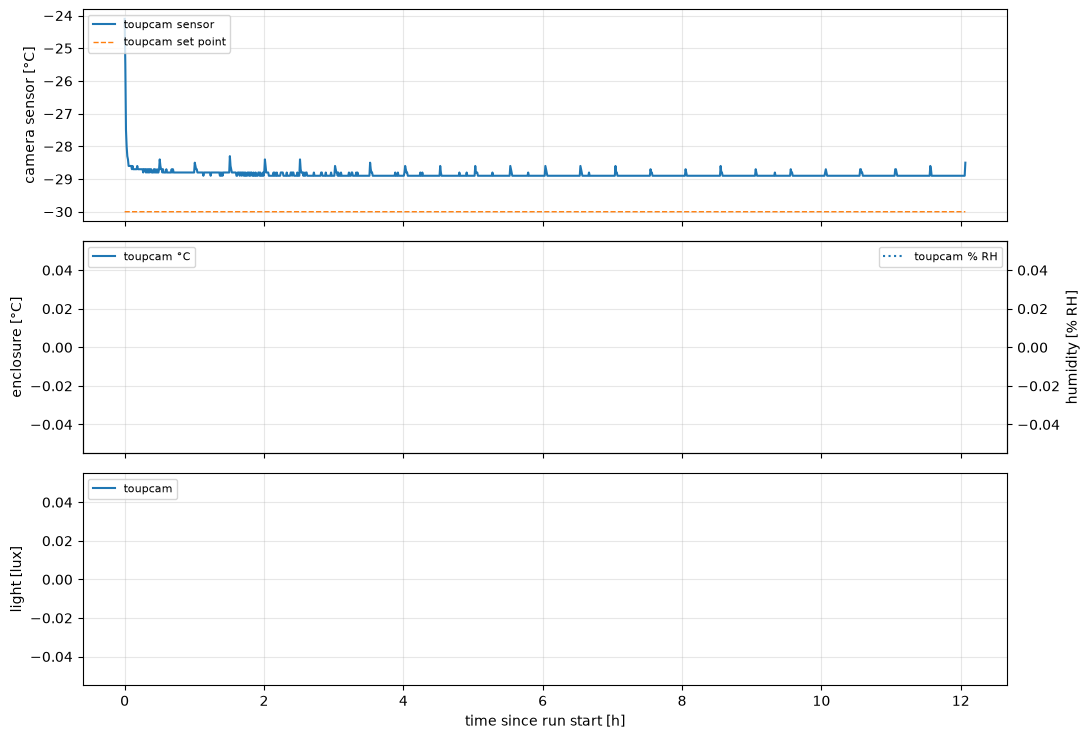

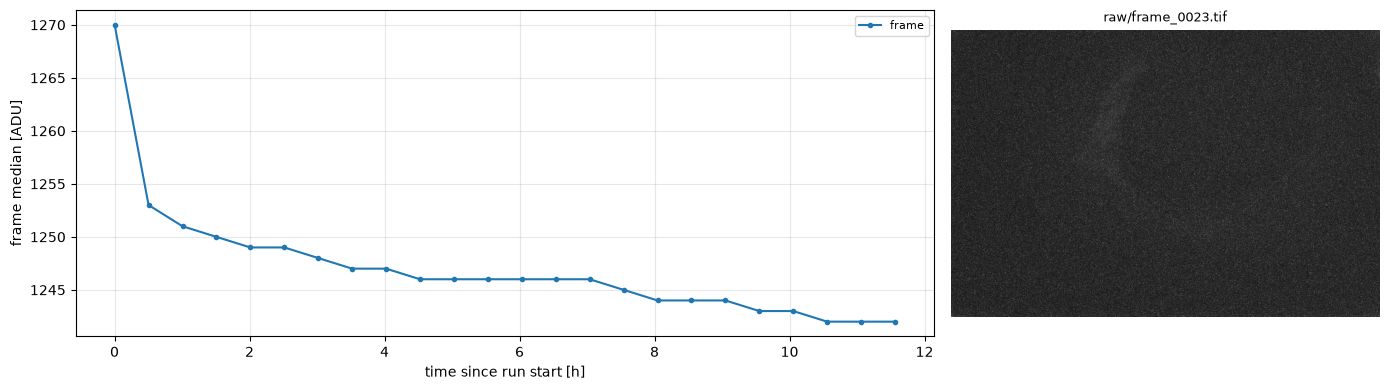

2026-10-25 02:31:28  saved frame_0019 (1800 s, median 1243.0)
2026-10-25 02:01:37  saved frame_0020 (1800 s, median 1243.0)
2026-10-25 02:31:47  saved frame_0021 (1800 s, median 1242.0)
2026-10-25 03:01:57  saved frame_0022 (1800 s, median 1242.0)
2026-10-25 03:32:06  saved frame_0023 (1800 s, median 1242.0)
2026-10-25 03:32:06  acquisition done: 24 frames
acquisition finished: done


In [50]:
bp.dashboard(run.dir, acq, refresh_s=15)

## Stop

Interrupt the dashboard cell first (■): the kernel runs one cell at a time. This cancels the running
exposure on the server. Frames already saved stay on disk.

In [51]:
acq.stop()
print(acq.state)

{'phase': 'done', 'detail': '24 frames', 'step': 0, 'frame': 23, 'error': None, 'started': '2026-10-24T16:28:11', 'finished': '2026-10-25T03:32:06'}


## Finish

Stops the environment log and stores the camera state at the end. Run it after the acquisition has
finished or was stopped.

In [52]:
env.stop()
run.save_json("camera_end.json", bp.parameters(client, DETECTOR)[1])
run.log("run finished")

2026-10-25 03:32:23  run finished


## Analysis and report

Works on any run folder: point `RUN_DIR` at an older run to redraw it. Everything is read from the
files in that folder and written back to it (`figures/`, `analysis.csv`, `summary.json`,
`README.md`), so re-running these cells never loses data.

1. Show a frame and read off a **sample** ROI on the leaf and a **background** ROI next to it, as
   `[x, y, width, height]` in pixels of the saved frame.
2. Store the ROIs and redraw.

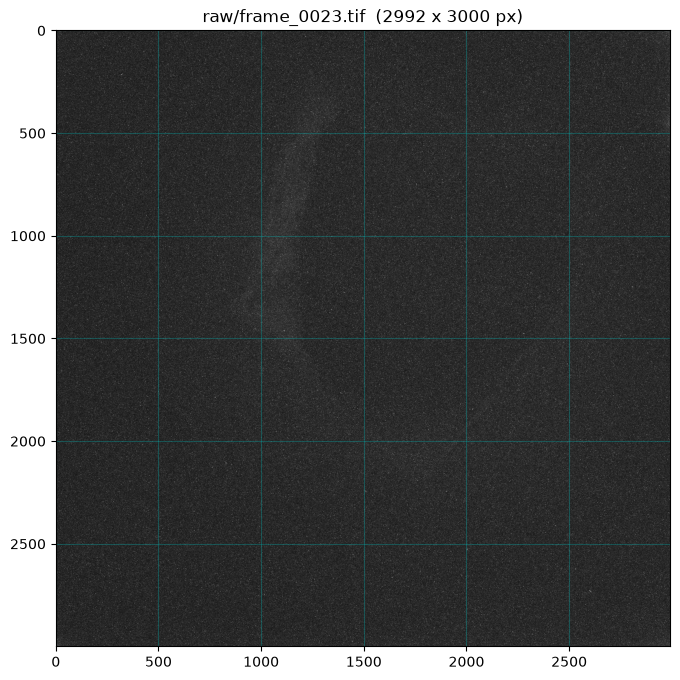

In [53]:
RUN_DIR = run.dir           # or e.g. Path("data/E4_touptek_long_exposure/<run folder>")
bp.show_frame(RUN_DIR, index=-1);

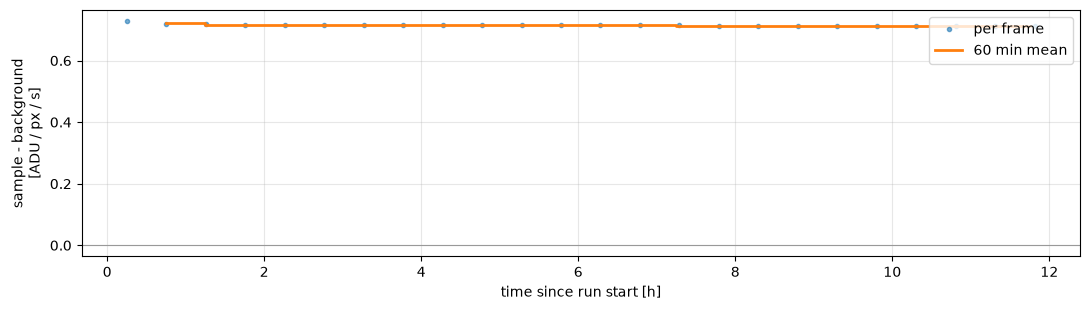

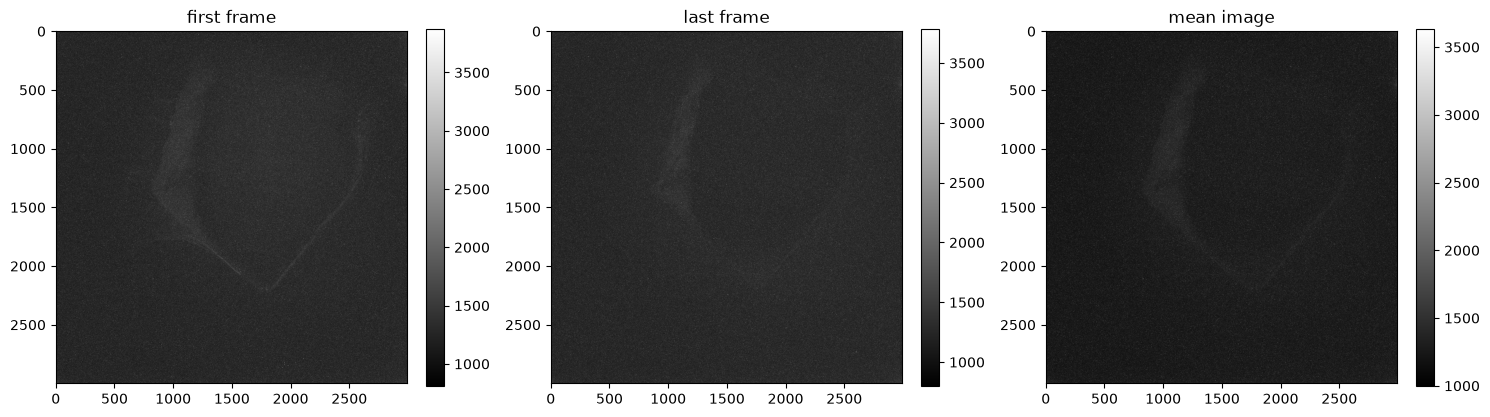

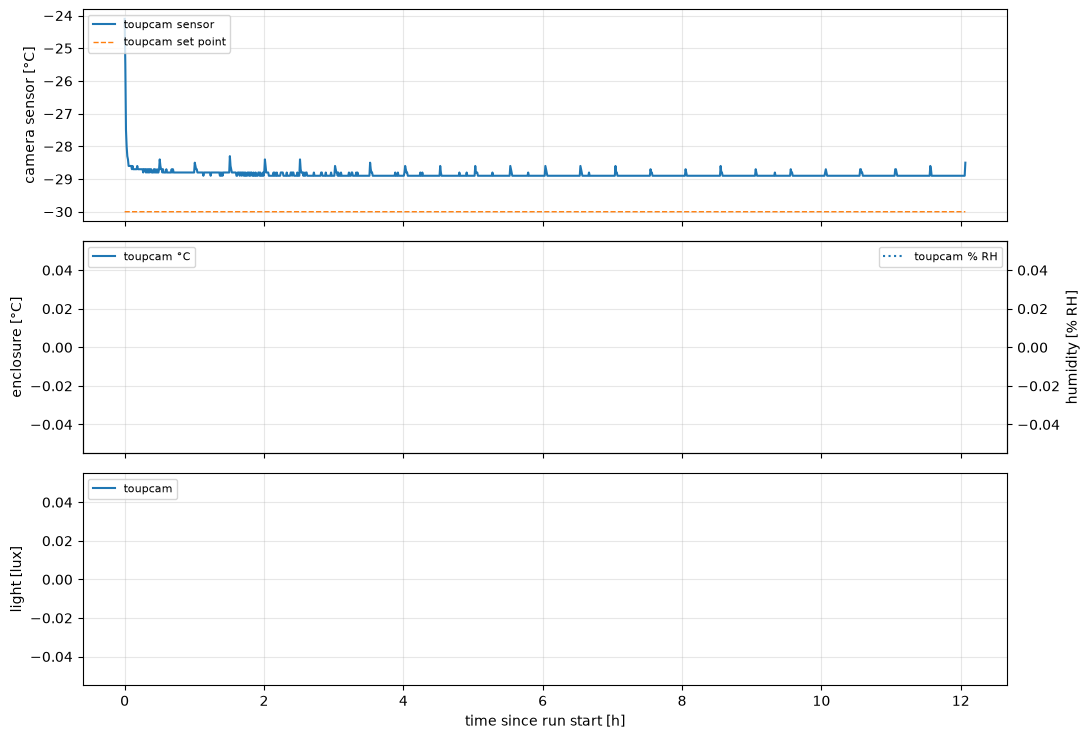

{'frames': 24,
 'mode': 'integrated',
 'unit': 'ADU / px / s',
 'total_exposure_h': 12.0,
 'time_axis': 'since run start',
 'rois': {'sample': None, 'background': None},
 'warnings': ['no sample ROI set: whole frame used',
  'no background ROI or offset: rates include the camera offset'],
 'rate': 0.7148745954157274,
 'rate_error': 0.0006613945698476197,
 'camera_temperature_c_min_max': [-28.9, -24.1]}

In [54]:
bp.set_rois(RUN_DIR, {"sample": None, "background": None})   # e.g. {"sample": [80, 90, 60, 60], "background": [10, 10, 40, 40]}
summary = bp.redraw(RUN_DIR, show=True)
summary

The run folder now holds `README.md` with this summary and the figures, and `report.ipynb`, which
redraws them from that folder alone (it imports the copy of `biophoton.py` stored with the run).